2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。


# BRCA external validation — pan-cancer Hist2Pheno (Virchow2 A2)

Virchow2 A2 uses a 14 px crop (7 µm after rescale to 0.5 µm/px). Run `demo_virchow2.sh`. UNI predictions stay in `pred_pancancer_section`.


Three HE + StarDist slides under `data/Visium/BRCA` (**no cell-type GT**):

| Sample | HE | µm/px |
|--------|----|-------|
| `GSM7782699_tissue_image` | OME TIFF | ~0.548 (OME PhysicalSize) |
| `200715_BC_SA2_C_D_V19F24-113.B1-Spot000001` | pathology JPEG → Visium `V10F24-113_B1` | ~0.172 (Visium × HE÷SR) |
| `200219_BC_SA3_V19T26-031_CE_V4-Spot000001` | pathology JPEG → Visium `V19T26-031_D1` | ~0.172 (Visium × HE÷SR) |

Predictions use the pan-cancer **cross-section** checkpoint
`A2_adjacent_spatial_k8mean` (L1 / L12 / L2), spatial k=8.
Cohort helper: `code/External_val/BRCA/brca_external.py` (mixed HE suffix + per-sample mpp).
Zenodo JPEGs are ~3.333× Space Ranger fullres — do **not** use raw `65/spot_diameter` on them.

```bash
conda activate SeededNTM
bash code/External_val/BRCA/demo_virchow2.sh dry-run
SAMPLE=200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 bash code/External_val/BRCA/demo_virchow2.sh all
```

Outputs: `data/Visium/BRCA/pred_virchow2_A2/`.


In [1]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
import os
os.environ["VIRCHOW2_CKPT"] = str(REPO / "data/PanCancer/result_virchow2_A2/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt")
STAR_PROB_MIN = 0.0  # 2026.10.28, set above 0 to store a separate _probXX folder
import os as _prob_os
_prob_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
os.environ["VIRCHOW2_PRED_DIRNAME"] = "pred_virchow2_A2"
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA"))

import brca_external as brca_ext
brca_ext.use_embedder("virchow2")

PRED_ROOT = brca_ext.PRED_ROOT
composition_table = brca_ext.composition_table
discover_samples = brca_ext.discover_samples
geometry = brca_ext.geometry
sample_paths = brca_ext.sample_paths
ensure_l2_probs = brca_ext.ensure_l2_probs
plot_spatial = brca_ext.plot_spatial
plot_composition = brca_ext.plot_composition
plot_roi_spatial = brca_ext.plot_roi_spatial
plot_roi_composition = brca_ext.plot_roi_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (20.4, 7.8)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"({g['mpp_source']})  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  HE: {p['he'].name}  pred exists: {p['pred'].is_file()}")

# 2026.10.28, mandatory current-input preflight / 后续直接读 h5ad 的图表也不得绕过上游
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = str(globals().get("STAR_PROB_MIN", 0.0))
if "ensure_l2_probs" in globals():
    _owner = ensure_l2_probs.__self__
    _current_samples = list(samples) if "samples" in globals() else _owner.discover_samples()
    _owner.cmd_predict(_current_samples, force=False, allow_cpu=True)
elif "ue" in globals():
    ue.cmd_predict(COHORT, samples, cuda_device=_pipeline_os.environ.get("CUDA_DEVICE", "0"),
                   force=False, allow_cpu=True, embedder=EMBEDDER)
else:
    raise RuntimeError("No current prediction validator; run the setup cell first")


200219_BC_SA3_V19T26-031_CE_V4-Spot000001  mpp=0.1721 µm/px  (Visium V19T26-031_D1: (65/spot_diameter_fullres=113.3115) / HE÷SR=3.3333)  native14=2.41 µm  after rescale=7.0 µm  scale=0.3442
  HE: 200219_BC_SA3_V19T26-031_CE_V4-Spot000001.jpg  pred exists: False
200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  mpp=0.1720 µm/px  (Visium V10F24-113_B1: (65/spot_diameter_fullres=113.3916) / HE÷SR=3.3333)  native14=2.41 µm  after rescale=7.0 µm  scale=0.3439
  HE: 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001.jpg  pred exists: False
GSM7782699_tissue_image  mpp=0.5476 µm/px  (OME PhysicalSize)  native14=7.67 µm  after rescale=7.0 µm  scale=1.0952
  HE: GSM7782699_tissue_image.tif  pred exists: False
V1_Breast_Cancer_Block_A_Section_1_image  mpp=0.3662 µm/px  (Visium V1_Breast_Cancer_Block_A_Section_1_image: (65/spot_diameter_fullres=177.4817) / HE÷SR=1.0000)  native14=5.13 µm  after rescale=7.0 µm  scale=0.7325
  HE: V1_Breast_Cancer_Block_A_Section_1_image.tif  pred exists: False
[features] 200219

[2026-11-01 20:16:21] INFO - Using device: cuda:0
[2026-11-01 20:16:21] INFO - Output contract: storage=h5ad; save_patch_images=False
[2026-11-01 20:16:21] INFO - H5AD target: /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14/embeddings.h5ad; published only after this section completes
[2026-11-01 20:16:21] INFO - Progress names identify cells; no per-nucleus .pth files are written in h5ad mode
[2026-11-01 20:16:21] INFO - PNG crops disabled; existing images/legacy archives are not deleted
[2026-11-01 20:16:21] INFO - Loaded CSV with shape: (391069, 3)
[2026-11-01 20:16:21] INFO - Mapped StarDist centroid_x/centroid_y -> pxl_row/pxl_col (HE full-res px); scale_image=True, scale=0.3442 (391,069 detections)
[2026-11-01 20:16:21] INFO - tissue_position: 
     centroid_x   centroid_y  ...  pxl_row_in_fullres  pxl_col_in_fullres
0  3747.742317  3554.160309  ...         1289.929319

[features] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001 wrote 391,069 embeddings
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 391,069 points
  KDTree matched 391,069 / 391,069 cells (100.00%).
[h5ad] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001: 391,069/391,069 nuclei, 1280 features
Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_virchow2_A2/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
[features] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  mpp=0.1720  scale=0.3439  patch=7.0µm  nuclei=372,413


[2026-11-01 22:11:13] INFO - Using device: cuda:0
[2026-11-01 22:11:13] INFO - Output contract: storage=h5ad; save_patch_images=False
[2026-11-01 22:11:13] INFO - H5AD target: /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200715_BC_SA2_C_D_V19F24-113.B1-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14/embeddings.h5ad; published only after this section completes
[2026-11-01 22:11:13] INFO - Progress names identify cells; no per-nucleus .pth files are written in h5ad mode
[2026-11-01 22:11:13] INFO - PNG crops disabled; existing images/legacy archives are not deleted
[2026-11-01 22:11:13] INFO - Loaded CSV with shape: (372413, 3)
[2026-11-01 22:11:14] INFO - Mapped StarDist centroid_x/centroid_y -> pxl_row/pxl_col (HE full-res px); scale_image=True, scale=0.3439 (372,413 detections)
[2026-11-01 22:11:14] INFO - tissue_position: 
     centroid_x   centroid_y  ...  pxl_row_in_fullres  pxl_col_in_fullres
0  3267.569519  3665.911385  ...         1123.85034

[features] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 wrote 372,413 embeddings
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200715_BC_SA2_C_D_V19F24-113.B1-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 372,413 points
  KDTree matched 372,413 / 372,413 cells (100.00%).
[h5ad] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001: 372,413/372,413 nuclei, 1280 features
[features] GSM7782699_tissue_image  mpp=0.5476  scale=1.0952  patch=7.0µm  nuclei=281,051


[2026-11-01 23:13:58] INFO - Using device: cuda:0
[2026-11-01 23:13:58] INFO - Output contract: storage=h5ad; save_patch_images=False
[2026-11-01 23:13:58] INFO - H5AD target: /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/GSM7782699_tissue_image/ImgEmbeddings_all_stardist/sc_pth_14_14/embeddings.h5ad; published only after this section completes
[2026-11-01 23:13:58] INFO - Progress names identify cells; no per-nucleus .pth files are written in h5ad mode
[2026-11-01 23:13:58] INFO - PNG crops disabled; existing images/legacy archives are not deleted
[2026-11-01 23:13:58] INFO - Loaded CSV with shape: (281051, 3)
[2026-11-01 23:13:58] INFO - Mapped StarDist centroid_x/centroid_y -> pxl_row/pxl_col (HE full-res px); scale_image=True, scale=1.0952 (281,051 detections)
[2026-11-01 23:13:58] INFO - tissue_position: 
     centroid_x   centroid_y  ...  pxl_row_in_fullres  pxl_col_in_fullres
0  2192.398026  3158.236885  ...         2401.052908         3458.8125

[features] GSM7782699_tissue_image wrote 281,049 embeddings
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/GSM7782699_tissue_image/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 281,049 points
  KDTree matched 281,049 / 281,051 cells (100.00%).
[h5ad] GSM7782699_tissue_image: 281,049/281,051 nuclei, 1280 features
[features] V1_Breast_Cancer_Block_A_Section_1_image  mpp=0.3662  scale=0.7325  patch=7.0µm  nuclei=423,190


[2026-11-02 00:31:44] INFO - Using device: cuda:0
[2026-11-02 00:31:44] INFO - Output contract: storage=h5ad; save_patch_images=False
[2026-11-02 00:31:44] INFO - H5AD target: /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/V1_Breast_Cancer_Block_A_Section_1_image/ImgEmbeddings_all_stardist/sc_pth_14_14/embeddings.h5ad; published only after this section completes
[2026-11-02 00:31:44] INFO - Progress names identify cells; no per-nucleus .pth files are written in h5ad mode
[2026-11-02 00:31:44] INFO - PNG crops disabled; existing images/legacy archives are not deleted
[2026-11-02 00:31:44] INFO - Loaded CSV with shape: (423190, 3)
[2026-11-02 00:31:44] INFO - Mapped StarDist centroid_x/centroid_y -> pxl_row/pxl_col (HE full-res px); scale_image=True, scale=0.7325 (423,190 detections)
[2026-11-02 00:31:44] INFO - tissue_position: 
     centroid_x   centroid_y  ...  pxl_row_in_fullres  pxl_col_in_fullres
0   858.555450   404.077168  ...          628.866008 

[features] V1_Breast_Cancer_Block_A_Section_1_image wrote 423,162 embeddings
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/V1_Breast_Cancer_Block_A_Section_1_image/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 423,162 points
  KDTree matched 423,162 / 423,190 cells (99.99%).
[h5ad] V1_Breast_Cancer_Block_A_Section_1_image: 423,162/423,190 nuclei, 1280 features


In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: bash code/External_val/BRCA/demo_virchow2.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))


[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 391,069 points
  KDTree matched 391,069 / 391,069 cells (100.00%).
[h5ad] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001: 391,069/391,069 nuclei, 1280 features
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_Virchow2/200715_BC_SA2_C_D_V19F24-113.B1-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 372,413 points
  KDTree matched 372,413 / 372,413 cells (100.00%).
[h5ad] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001: 372,413/372,413 nuclei, 1280 features

===== L1 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Epithelial                                      0.526   
Stromal                                         0.161   
Endothelial                                     0.138   
Immune                                          0.173   
Neural                                          0.002   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Epithelial                                       0.932   
Stromal                                          0.008   
Endothelial                                      0.031   
Immune                                           0.025   
Neural                                           0.003   

                                                                              \
sample      GSM7782699_tissue_image V1_Breast_Cancer_Block_A_Section_1_image   
class                                                                          
Epithelial                    0.191                                    0.126   
Stromal                       0.164                                    0.375   
Endothelial                   0.370                                    0.230   
Immune                        0.264                                    0.269   
Neural                        0.011                                    0.000   

                                            mean_conf  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Epithelial                                      0.747   
Stromal                                         0.493   
Endothelial                                     0.500   
Immune                                          0.568   
Neural                                          0.473   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Epithelial                                       0.867   
Stromal                                          0.472   
Endothelial                                      0.484   
Immune                                           0.508   
Neural                                           0.521   

                                                                              \
sample      GSM7782699_tissue_image V1_Breast_Cancer_Block_A_Section_1_image   
class                                                                          
Epithelial                    0.605                                    0.688   
Stromal                       0.493                                    0.493   
Endothelial                   0.542                                    0.521   
Immune                        0.598                                    0.535   
Neural                        0.536                                    0.504   

                                                    n  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Epithelial                                   205857.0   
Stromal                                       62800.0   
Endothelial                                   54016.0   
Immune                                        67688.0   
Neural                                          708.0   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Epithelial                                    347253.0   
Stromal                                         3087.0   
Endothelial                                    11709.0   
Immune                                          9289.0   
Neural                                          1075.0  


===== L12 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Tumor                                           0.160   
Stromal                                         0.185   
Epithelial                                      0.255   
Myeloid                                         0.239   
T_cell                                          0.111   
Endothelial                                     0.044   
B_Plasma                                        0.006   
Neural                                            NaN   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Tumor                                            0.809   
Stromal                                          0.009   
Epithelial                                       0.121   
Myeloid                                          0.039   
T_cell                                           0.015   
Endothelial                                      0.008   
B_Plasma                                         0.000   
Neural                                           0.000   

                                                                              \
sample      GSM7782699_tissue_image V1_Breast_Cancer_Block_A_Section_1_image   
class                                                                          
Tumor                         0.156                                    0.102   
Stromal                       0.255                                    0.445   
Epithelial                    0.073                                    0.023   
Myeloid                       0.190                                    0.122   
T_cell                        0.138                                    0.234   
Endothelial                   0.143                                    0.064   
B_Plasma                      0.046                                    0.011   
Neural                        0.000                                      NaN   

                                            mean_conf  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Tumor                                           0.611   
Stromal                                         0.440   
Epithelial                                      0.673   
Myeloid                                         0.422   
T_cell                                          0.488   
Endothelial                                     0.394   
B_Plasma                                        0.424   
Neural                                            NaN   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Tumor                                            0.768   
Stromal                                          0.395   
Epithelial                                       0.628   
Myeloid                                          0.416   
T_cell                                           0.439   
Endothelial                                      0.377   
B_Plasma                                         0.334   
Neural                                           0.352   

                                                                              \
sample      GSM7782699_tissue_image V1_Breast_Cancer_Block_A_Section_1_image   
class                                                                          
Tumor                         0.555                                    0.632   
Stromal                       0.428                                    0.411   
Epithelial                    0.472                                    0.470   
Myeloid                       0.398                                    0.347   
T_cell                        0.491                                   


===== L2 =====


fraction  \
sample            200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                         
Tumor                                                 0.178   
Fibroblast                                            0.075   
Endothelial                                           0.081   
Macrophage                                            0.141   
Injury_epithelial                                     0.137   
Epithelial                                            0.123   
Myofibroblast                                         0.063   
B_cell                                                0.041   
Tregs                                                 0.001   
DCIS                                                  0.004   
CD4_T                                                 0.026   
Myoepithelial                                         0.001   
Neutrophil                                            0.054   
Stromal                                               0.008   
CD8_T                                                 0.049   
Plasma                                                0.001   
DC                                                    0.001   
Alveolar                                              0.013   
NK                                                    0.002   
Neural                                                0.000   

                                                              \
sample            200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                          
Tumor                                                  0.696   
Fibroblast                                             0.001   
Endothelial                                            0.020   
Macrophage                                             0.020   
Injury_epithelial                                      0.035   
Epithelial                                             0.049   
Myofibroblast                                          0.000   
B_cell                                                 0.003   
Tregs                                                  0.000   
DCIS                                                   0.082   
CD4_T                                                  0.002   
Myoepithelial                                          0.065   
Neutrophil                                             0.010   
Stromal                                                0.009   
CD8_T                                                  0.005   
Plasma                                                 0.000   
DC                                                     0.000   
Alveolar                                               0.002   
NK                                                     0.000   
Neural                                                 0.000   

                                           \
sample            GSM7782699_tissue_image   
class                                       
Tumor                               0.168   
Fibroblast                          0.038   
Endothelial                         0.223   
Macrophage                          0.019   
Injury_epithelial                   0.001   
Epithelial                          0.091   
Myofibroblast                       0.114   
B_cell                              0.109   
Tregs                               0.015   
DCIS                                0.000   
CD4_T                               0.078   
Myoepithelial                         NaN   
Neutrophil                          0.056   
Stromal                             0.056   
CD8_T                               0.001   
Plasma                              0.021   
DC                                  0.007   
Alveolar                            0.000   
NK                                  0.001   
Neural                              0.001   

                                                            \
sample            V1_Breast_Ca

[plot] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001  nuclei=391,069  neighbor=23.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  nuclei=372,413  neighbor=23.4px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] GSM7782699_tissue_image  nuclei=281,049  neighbor=12.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] V1_Breast_Cancer_Block_A_Section_1_image  nuclei=423,162  neighbor=15.7px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points


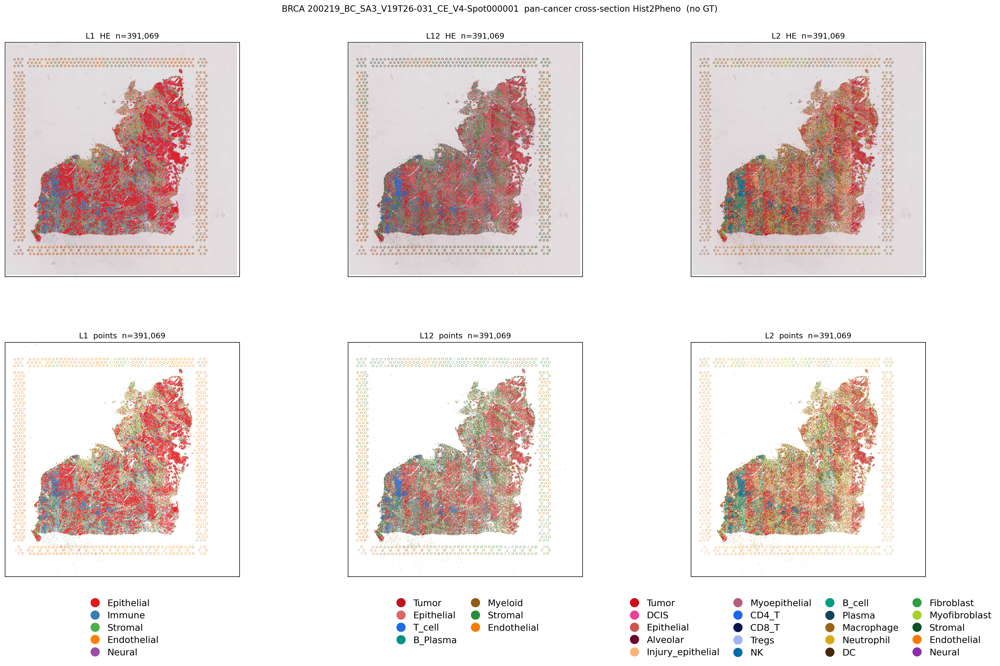

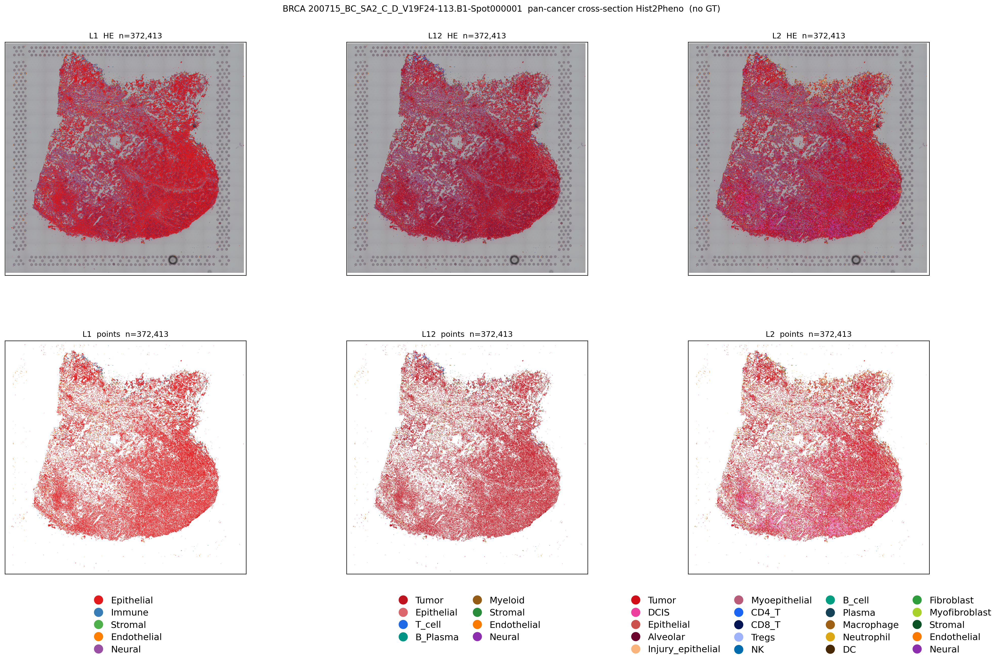

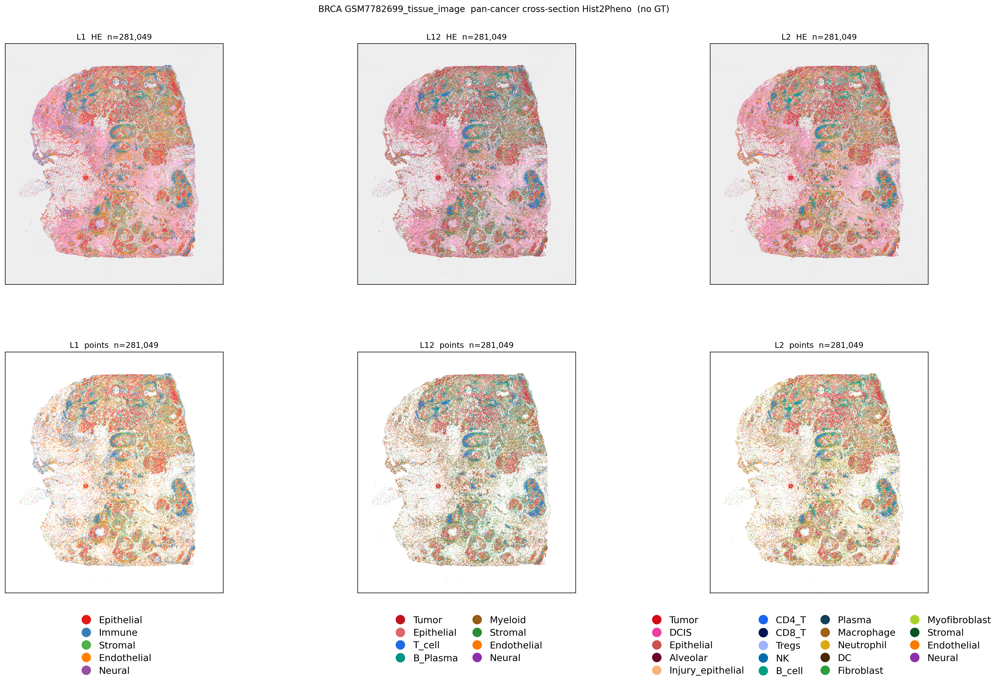

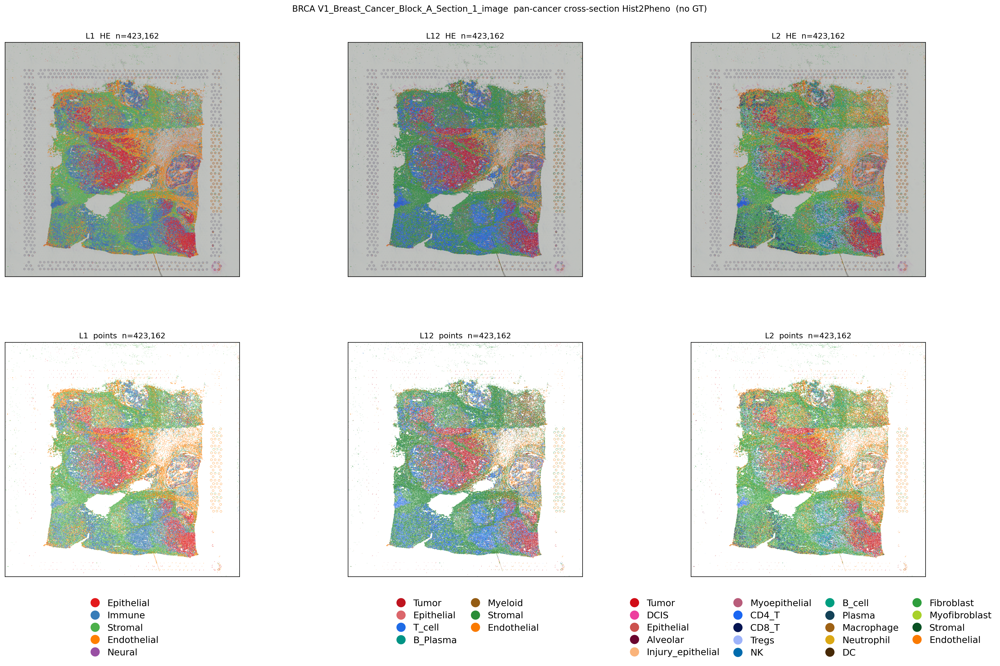

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


### Single section + QuPath ROI

Section: `200219_BC_SA3_V19T26-031_CE_V4-Spot000001`  
ROI: `data/Visium/BRCA/HE_images/selected_rectangle_coordinates.tsv` (native HE pixels).


In [1]:
# # One section only (full slide L1 / L12 / L2)
# SAMPLE_ROI = "200219_BC_SA3_V19T26-031_CE_V4-Spot000001"
# if SAMPLE_ROI not in samples:
#     raise FileNotFoundError(
#         f"{SAMPLE_ROI} not in discover_samples(): {samples}. "
#         "Run: SAMPLE=... bash code/External_val/BRCA/demo_virchow2.sh all"
#     )
# if not sample_paths(SAMPLE_ROI)["pred"].is_file():
#     raise FileNotFoundError(sample_paths(SAMPLE_ROI)["pred"])

# for fig in plot_spatial(
#     [SAMPLE_ROI],
#     figsize=FIGSIZE,
#     dpi=DPI,
#     he_max_side=HE_MAX_SIDE,
#     marker_px=MARKER_PX,
#     save=SAVE_FIGURES,
#     save_dpi=SAVE_DPI,
# ):
#     display(fig)
#     plt.close(fig)


ROI 200219_BC_SA3_V19T26-031_CE_V4-Spot000001: x=[18296,20794] y=[39862,41783]  nuclei=2,595  MARKER_PX_ROI=10.0


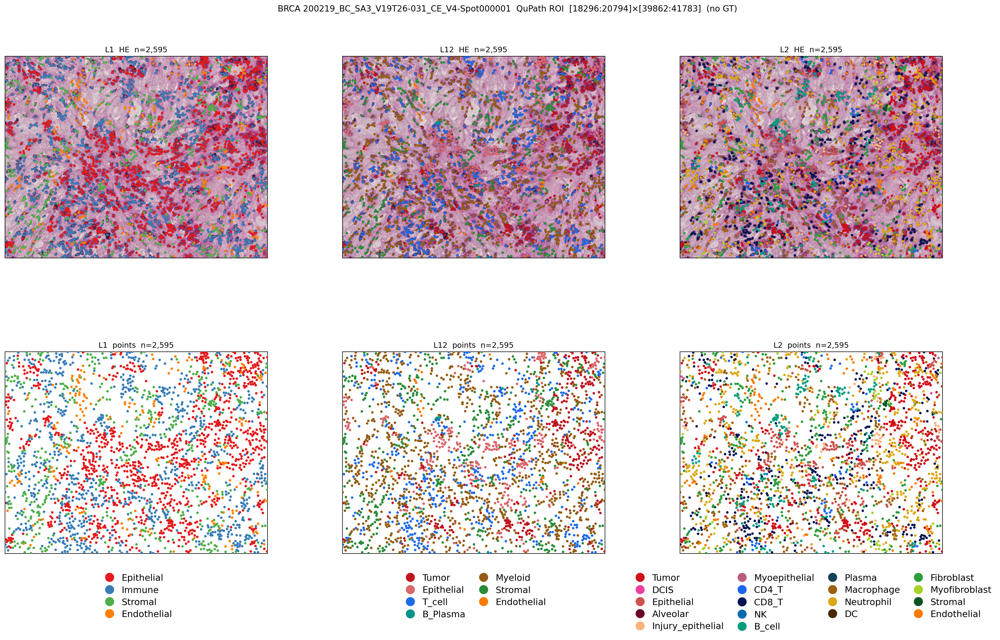

In [5]:
# ROI from QuPath rectangle → L1 / L12 / L2 on cropped HE
# Full-slide MARKER_PX (~1) is too small once the view is a ~2.5k×2k crop.
ROI_TSV = REPO / "data" / "Visium" / "BRCA" / "HE_images" / "selected_rectangle_coordinates.tsv"
MARKER_PX_ROI = max(float(MARKER_PX) * 5.0, 10.0)
fig_h = float(FIGSIZE[1]) * 1.9 if FIGSIZE[1] <= 8.5 else float(FIGSIZE[1])

fig, pred, in_roi, roi = plot_roi_spatial(
    SAMPLE_ROI,
    ROI_TSV,
    marker_px=MARKER_PX_ROI,
    dpi=DPI,
    figsize=(float(FIGSIZE[0]), fig_h),
    legend_markersize=13,
    legend_fontsize=13,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
print(
    f"ROI {SAMPLE_ROI}: x=[{roi['x_min_px']:.0f},{roi['x_max_px']:.0f}] "
    f"y=[{roi['y_min_px']:.0f},{roi['y_max_px']:.0f}]  "
    f"nuclei={int(in_roi.sum()):,}  MARKER_PX_ROI={MARKER_PX_ROI:.1f}"
)
display(fig)
plt.close(fig)


head,L1,L12,L2
class,,,
Alveolar,0.000,0.000,0.008
B_Plasma,0.000,0.008,0.000
B_cell,0.000,0.000,0.072
CD4_T,0.000,0.000,0.022
CD8_T,0.000,0.000,0.126
DC,0.000,0.000,0.003
DCIS,0.000,0.000,0.001
Endothelial,0.087,0.011,0.066
Epithelial,0.396,0.114,0.082


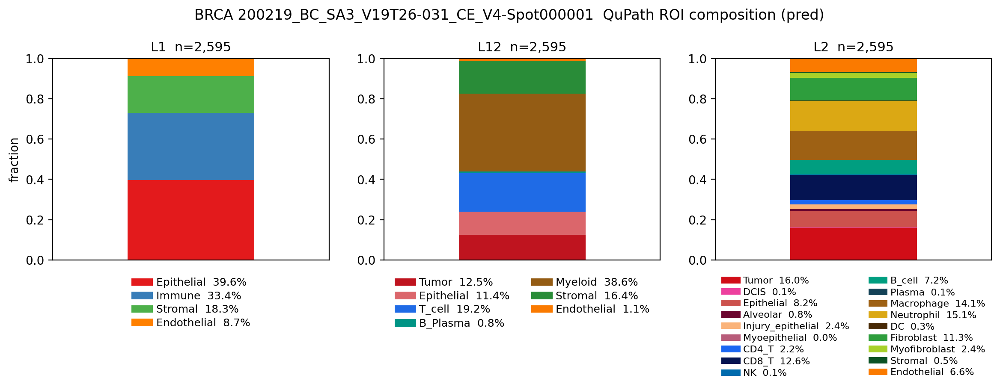

In [6]:
# ROI cell-type composition (100% stacked): L1 / L12 / L2
fig, comp_df = plot_roi_composition(
    SAMPLE_ROI,
    pred=pred,
    in_roi=in_roi,
    dpi=DPI,
    figsize=(12.0, 4.2),
    legend_fontsize_l1=9,
    legend_fontsize_l2=8,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
display(comp_df.pivot_table(index="class", columns="head", values="fraction").fillna(0).round(3))
display(fig)
plt.close(fig)


In [7]:
# for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
#     display(fig)
#     plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used: those members (AT1/AT2, activated fibrotic FBs, SPP1+ macrophages) are not pan-cancer L2 classes.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz` (first call reloads the cross-section checkpoint).

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS, as in the lung T-cell set. `spatial_HE` is native HE pixels, so R = **55 µm** is converted with **each sample's** `geometry(sample)['mpp_um']` (GSM ~0.548; Zenodo JPEGs ~0.172), not 0.5. Hotspots are the within-slide 95th percentile. TLS, SRI, and TNI each use a 1×3 row: abundance, the spatial score without markers, then the same spatial map with cyan candidate nuclei. The two spatial panels share one color scale.


In [8]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0  # lung notebook cross-dataset TLS radius
RECOMPUTE_NICHE = True  # 2026.10.28, legacy niche cache lacks provenance; recompute from verified current probabilities

BRCA_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),  # formula table only; cell below uses per-sample mpp
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA",
)
print("µm/px by sample:", {s: round(float(geometry(s)["mpp_um"]), 4) for s in samples})
display(hni.index_formula_table(BRCA_NICHE))


µm/px by sample: {'200219_BC_SA3_V19T26-031_CE_V4-Spot000001': 0.1721, '200715_BC_SA2_C_D_V19F24-113.B1-Spot000001': 0.172, 'GSM7782699_tissue_image': 0.5476, 'V1_Breast_Cancer_Block_A_Section_1_image': 0.3662}


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [9]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, BRCA_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        __import__("pipeline_provenance").publish_derived_h5ad(out,niche_path,paths["pred"], probabilities=probs, class_names=class_names, obs_names=pred.obs_names, parameters={"config":BRCA_NICHE,"mpp":mpp,"radius_um":TLS_RADIUS_UM},algorithm=hni.__file__)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_virchow2_A2/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_virchow2_A2/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/200219_BC_SA3_V19T26-031_CE_V4-Spot000001_niche_indices.h5ad  n=391,069
  TLS hotspot: {'n_cells_total': 391069, 'n_candidate_cells': 19554, 'fraction_candidate': 0.05000140640142788, 'max_tls_spatial': 0.2152644561816204, 'mean_tls_spatial_candidate': 0.14914861582366415, 'centroid_x': 14134.424535197251, 'centroid_y': 34702.021031521086}
  mean TLS=0.190  TLS_spatial=0.051  SRI=3.029  TNI=6.156
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_virchow2_A2/200715_BC_SA2_C_D_V19F24-113.B1-Spot000001/200715_BC_SA2_C_D_V19F24-113.B1-Spot000001_niche_indices.h5a

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_virchow2_A2/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,200219_BC_SA3_V19T26-031_CE_V4-Spot000001,391069,0.190,0.109,0.683,0.996,0.051,0.043,0.120,0.215,0.639,0.623,0.261,0.414,0.113,0.573
1,200715_BC_SA2_C_D_V19F24-113.B1-Spot000001,372413,0.048,0.019,0.196,0.960,0.013,0.008,0.038,0.147,0.577,0.583,0.241,0.389,0.038,0.207
2,GSM7782699_tissue_image,281049,0.283,0.211,0.800,0.998,0.075,0.070,0.147,0.213,0.645,0.639,0.215,0.353,0.129,0.677
3,V1_Breast_Cancer_Block_A_Section_1_image,423162,0.337,0.319,0.672,0.992,0.102,0.101,0.165,0.239,0.648,0.634,0.258,0.411,0.152,0.620


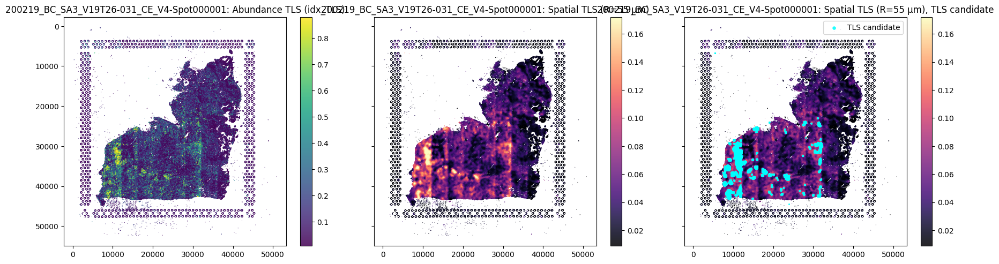

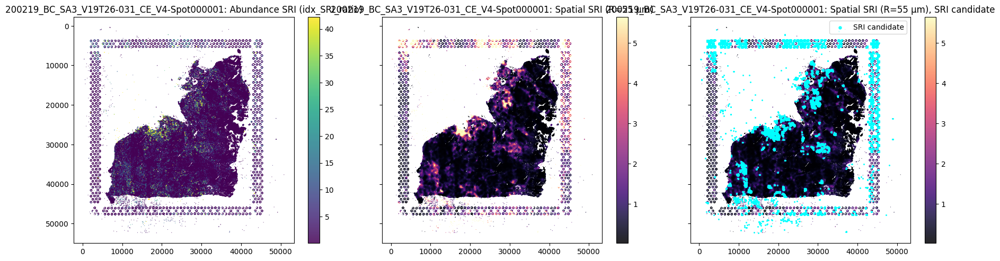

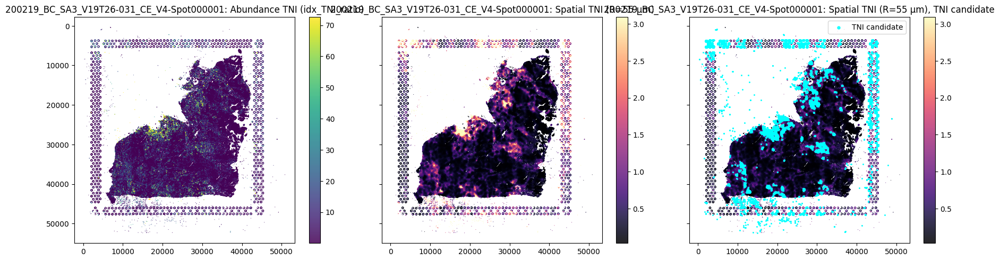

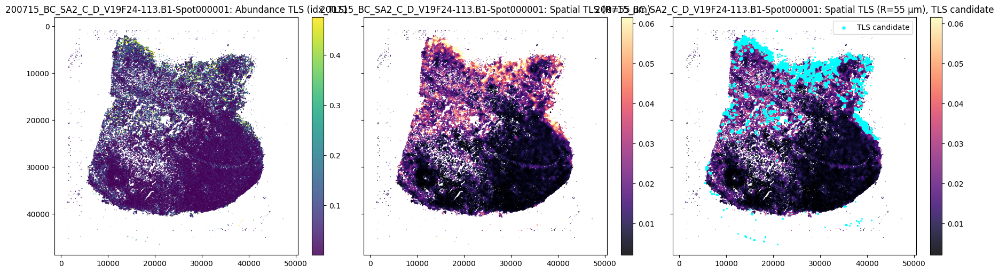

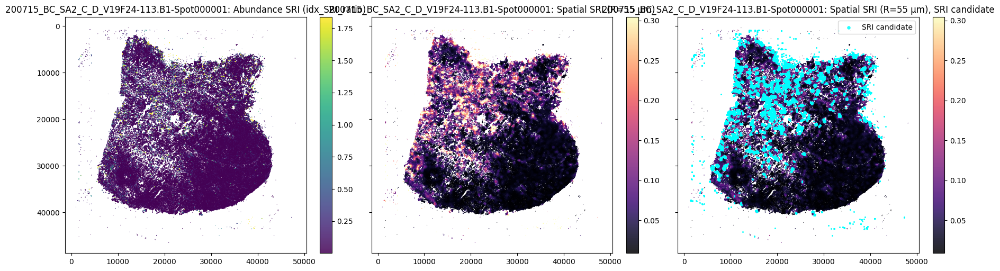

...

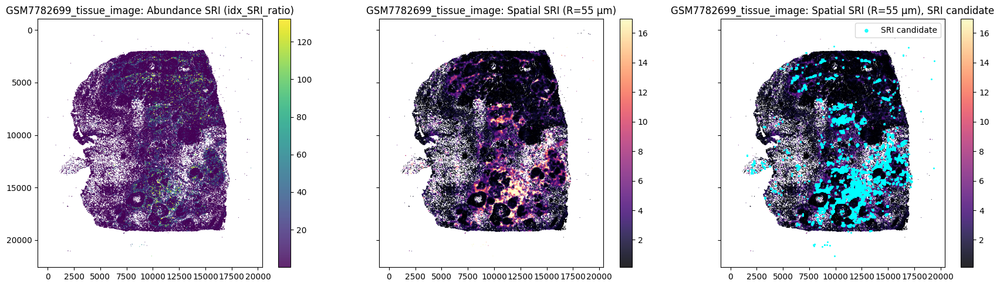

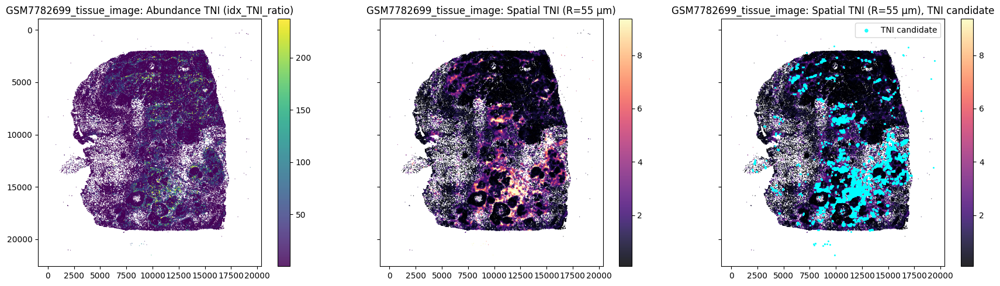

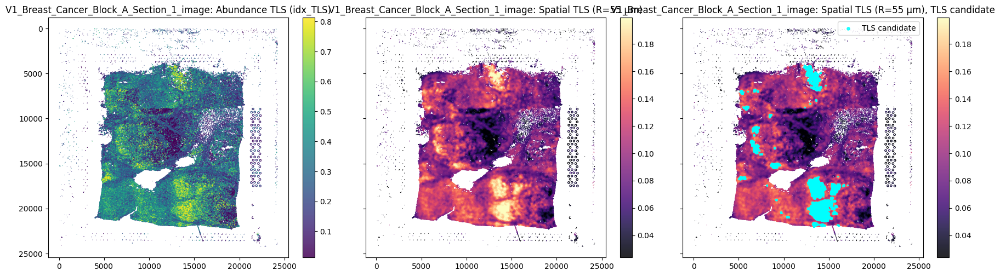

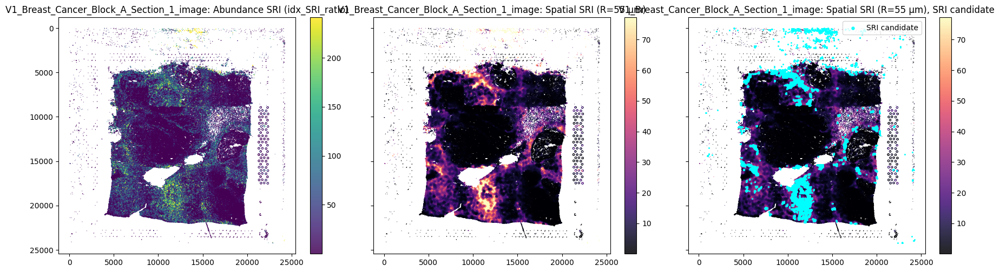

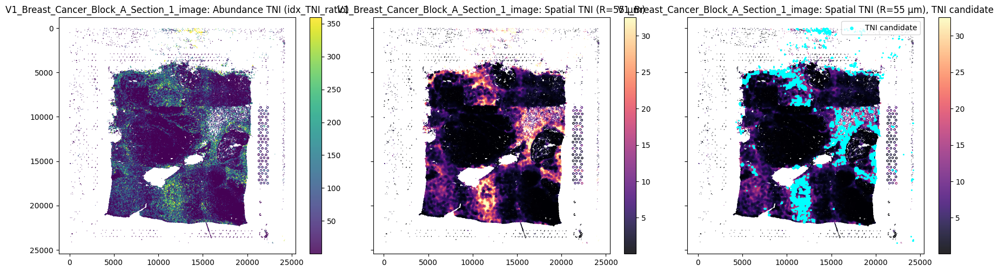

In [11]:
# import matplotlib.pyplot as plt
# import pandas as pd
# from IPython.display import display

# fig_dir = PRED_ROOT / "figures"
# fig_dir.mkdir(parents=True, exist_ok=True)


# def tls_score_row(df, sample: str) -> dict:
#     """Quantify abundance TLS vs spatial TLS on the same nuclei."""
#     a = df["idx_TLS"].to_numpy(dtype=float)
#     s = df["idx_TLS_spatial"].to_numpy(dtype=float)
#     a_hi = a >= np.percentile(a, 95)
#     s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
#     inter = int(np.logical_and(a_hi, s_hi).sum())
#     union = int(np.logical_or(a_hi, s_hi).sum())
#     n_a = int(a_hi.sum())
#     return {
#         "sample": sample,
#         "n": int(len(df)),
#         "TLS_mean": float(np.mean(a)),
#         "TLS_median": float(np.median(a)),
#         "TLS_p95": float(np.percentile(a, 95)),
#         "TLS_max": float(np.max(a)),
#         "TLS_spatial_mean": float(np.mean(s)),
#         "TLS_spatial_median": float(np.median(s)),
#         "TLS_spatial_p95": float(np.percentile(s, 95)),
#         "TLS_spatial_max": float(np.max(s)),
#         "pearson": float(np.corrcoef(a, s)[0, 1]),
#         "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
#         "top5_jaccard": (inter / union) if union else float("nan"),
#         "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
#         "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
#         "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
#     }


# quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
# tls_quant = pd.DataFrame(quant_rows)
# tls_quant_path = fig_dir / "tls_score_summary.csv"
# tls_quant.to_csv(tls_quant_path, index=False)
# print(tls_quant_path)
# display(tls_quant.round(3))

# for sample, df in niche_frames.items():
#     fig, axes = hdni.plot_tls_abundance_vs_spatial(
#         df,
#         sample,
#         radius_um=TLS_RADIUS_UM,
#         use_entropy=False,
#         split_spatial_candidates=True,
#         dpi=DPI,
#         save_dpi=SAVE_DPI,
#         point_size=0.15,
#         candidate_size=1.2,
#         save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#     )
#     display(fig)
#     plt.close(fig)

#     for abundance_col, spatial_col, candidate_col, tag in (
#         ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
#         ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
#     ):
#         fig, axes = hdni.plot_tls_abundance_vs_spatial(
#             df,
#             sample,
#             radius_um=TLS_RADIUS_UM,
#             abundance_col=abundance_col,
#             spatial_col=spatial_col,
#             candidate_col=candidate_col,
#             score_name=tag,
#             use_entropy=False,
#             split_spatial_candidates=True,
#             dpi=DPI,
#         save_dpi=SAVE_DPI,
#         point_size=0.15,
#             candidate_size=1.2,
#             save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
#         )
#         display(fig)
#         plt.close(fig)
